# GENIE BPC BrCa v1.0-public — questions Br1–Br6

Source: Jacob's *CBIO thoughts* deck, slides 15–18. Data: AACR Project GENIE BPC BrCa v1.0-public (Synapse).

**Conventions** (see `README.md`): index date = diagnosis of the index breast cancer, OS in months; treatment questions use OS from regimen start.
*X mut* = non-synonymous mutation on the earliest sequenced sample of the index cancer; `amp` / `homdel` / `fus` are separate. Patients are compared for a gene only if their panel covers it.
KM / log-rank ignore left truncation (as cBioPortal does); the Cox HR is left-truncated at the sequencing report (*HR (LT)*).

**Breast-specific caveat that matters for every question here:** PIK3CA mutations are enriched in HR+/HER2− disease and TP53 mutations in triple-negative and HER2+ disease. Any PIK3CA-vs-TP53 survival difference is therefore confounded by subtype unless the comparison is made within a subtype or adjusted for it. Both are shown.

Treatment comparisons use regimens started **at or after the first distant metastasis** (`met_setting`), so that adjuvant endocrine therapy is not mixed with metastatic therapy.

In [1]:
import sys, re, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "cbio_lib.py").exists())
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import cbio_lib as cb

cb.setup_plots()
warnings.filterwarnings("ignore")
pd.options.display.float_format = "{:.3g}".format
pd.options.display.width = 200
DS = "bpc_brca"
F = []

b = cb.BPC("BrCa")
pd.Series(b.summary())

cohort                            BrCa
patients                          1130
index_cancers                     1141
patients_with_2+_index_cancers      11
samples                           1221
samples_used                      1130
regimens                          6522
mutations_nonsyn                  6665
cna_profiled_samples              1198
sv_rows                            689
dtype: object

## Data pin

In [2]:
log = pd.read_csv(cb.DATA / "genie" / "download_log_nsclc_brca.csv")
print("release_version:", b.index.release_version.unique())
log[log.cohort == "BrCa"][[c for c in ["category", "filename", "synapse_id", "version", "md5"] if c in log.columns]]

release_version: ['1.0-public']


,category,filename,synapse_id,version,md5
38,docs,GENIE BPC BrCa_v1.0-public Analytic Data Guide...,syn71825209,2,8950b184f8f8716c7fade9722dc2019d
39,docs,GENIE BPC BrCa_v1.0-public_Release_Notes.pdf,syn71825210,1,a117f2acfe496972f1836153e757f1b7
40,docs,GENIE BPC BrCa_v1.0-public Variable Synopsis.xlsx,syn71825211,2,22e9f2864660558c209bfaa16d8d180a
41,analytic,patient_level_dataset.csv,syn71825315,1,eb0d7f104ecf19104331c28deb4a4ae6
42,analytic,cancer_level_dataset_index.csv,syn71825316,1,513150925caa26ddb95419852f3301f6
43,analytic,cancer_level_dataset_non_index.csv,syn71825308,1,f48606c25496ca3ffc7fdac618c9ce9d
44,analytic,cancer_panel_test_level_dataset.csv,syn71825309,1,bb937af4534ec85d6e64a2e7a296d11c
45,analytic,regimen_cancer_level_dataset.csv,syn71825310,1,5cc781c822fa6112cb39671f9d94ea6d
46,analytic,imaging_level_dataset.csv,syn71825313,1,00f72bc5b5abeb59366a75b6e2443c4c
47,analytic,med_onc_note_level_dataset.csv,syn71825312,1,b3904ed2b513457a1b41b14e3588f019


## Cohort and alteration matrix

In [3]:
S = b.survival_dx()
A = b.alterations()
display(cb.consort([
    ("Patients in release", len(b.patients)),
    ("Index breast cancer (first index cancer per patient)", len(b.index)),
    ("With a sequenced sample of the index cancer", int(S.entry.notna().sum())),
    ("With OS from diagnosis", int(S.time.notna().sum())),
]))
print(f"{b.n_multi_index} patients had two index cancers (first used); {A.n_unknown_panel} samples with unknown panel; "
      f"{int((S.entry >= S.time).sum())} patients with sequencing report after last follow-up (dropped from left-truncated models only).")
print(f"Deaths: {int(S.event.sum())} / {len(S)}.  Median OS from dx: {cb.km_table(S.assign(g='all'), 'g').median_months[0]} months.")
display(pd.concat([S.stage_dx.value_counts().rename("stage_dx"), S.bca_subtype.value_counts(dropna=False).rename("subtype")], axis=1).fillna(""))

,step,n,dropped
0,Patients in release,1130,0
1,Index breast cancer (first index cancer per pa...,1130,0
2,With a sequenced sample of the index cancer,1130,0
3,With OS from diagnosis,1130,0


11 patients had two index cancers (first used); 0 samples with unknown panel; 62 patients with sequencing report after last follow-up (dropped from left-truncated models only).
Deaths: 545 / 1130.  Median OS from dx: 93.7 months.


,stage_dx,subtype
Stage II,435,
Stage IV,240,
Stage I,221,
Stage III,220,
Stage I-III NOS,14,
"HR+, HER2-",,669
Triple Negative,,179
"HR+, HER2+",,138
"HR-, HER2+",,74
NaN,,70


,gene,kind,n_altered,n_tested,pct
0,TP53,mut,535,1130,47.3
1,PIK3CA,mut,322,1130,28.5
2,CCND1,amp,190,1105,17.2
3,ERBB2,amp,173,1105,15.7
4,GATA3,mut,156,1130,13.8
5,MYC,amp,141,1105,12.8
6,FGFR1,amp,133,1105,12
7,FGF19,amp,124,1105,11.2
8,FGF4,amp,119,1105,10.8
9,FGF3,amp,117,1105,10.6


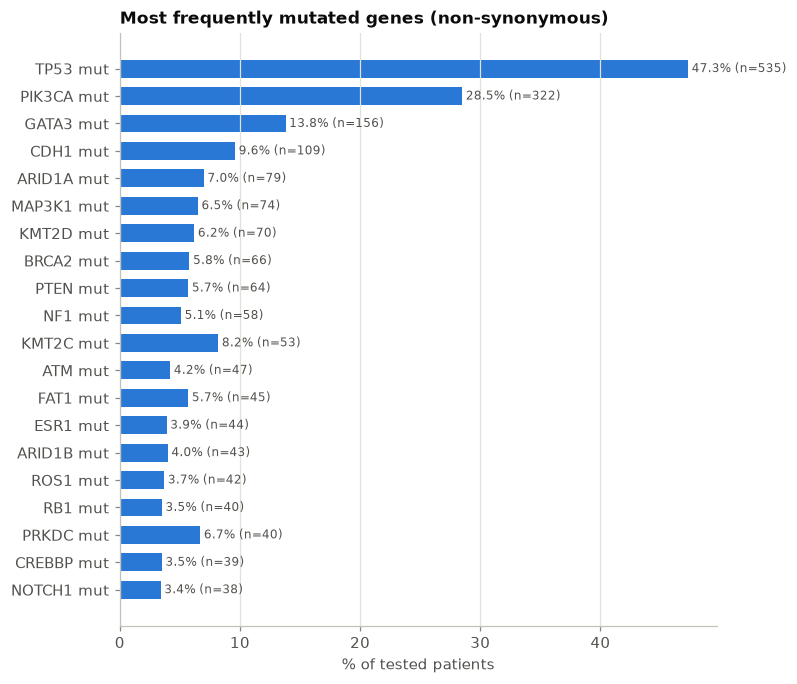

In [4]:
freq = A.frequency(kinds=("mut", "amp", "homdel", "fus"))
ax = cb.bar_freq(freq[freq.kind == "mut"], top=20, title="Most frequently mutated genes (non-synonymous)")
cb.save(DS, "cohort", table=freq, fig=ax.figure, slug="gene_frequency")
freq.head(15)

In [5]:
pik = A.status("PIK3CA")
tp53 = A.status("TP53")
grp = A.combo_groups(["PIK3CA", "TP53"], min_n=1, wt_label="neither")
grp = grp.replace({"PIK3CA": "PIK3CA only", "TP53": "TP53 only", "PIK3CA+TP53": "both"})
order4 = ["neither", "PIK3CA only", "TP53 only", "both"]
display(pd.crosstab(grp, S.bca_subtype.reindex(grp.index).fillna("unknown"), margins=True))

bca_subtype,"HR+, HER2+","HR+, HER2-","HR-, HER2+",Triple Negative,unknown,All
profile,,,,,,
PIK3CA only,16,183,1,2,12,214
TP53 only,50,153,50,149,25,427
both,30,52,10,13,3,108
neither,42,281,13,15,30,381
All,138,669,74,179,70,1130


## Br1 (replicate) — PIK3CA-mutant patients have significantly better OS than TP53-mutant patients
cBioPortal (slides 15–16) compared the PIK3CA-mutant and TP53-mutant groups; its group comparison excludes patients in both groups, so the primary replication is **PIK3CA-only vs TP53-only**. The four-group version and the subtype-adjusted model follow.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_tp53_vs_pik3ca,HR_adj_subtype_stage_age,p_adj
0,PIK3CA only,214,85,131,1,0.995,0.826,4.08e-11,2.15,2.65,6.93e-10
1,TP53 only,427,235,64.8,0.976,0.86,0.537,4.08e-11,2.15,2.65,6.93e-10


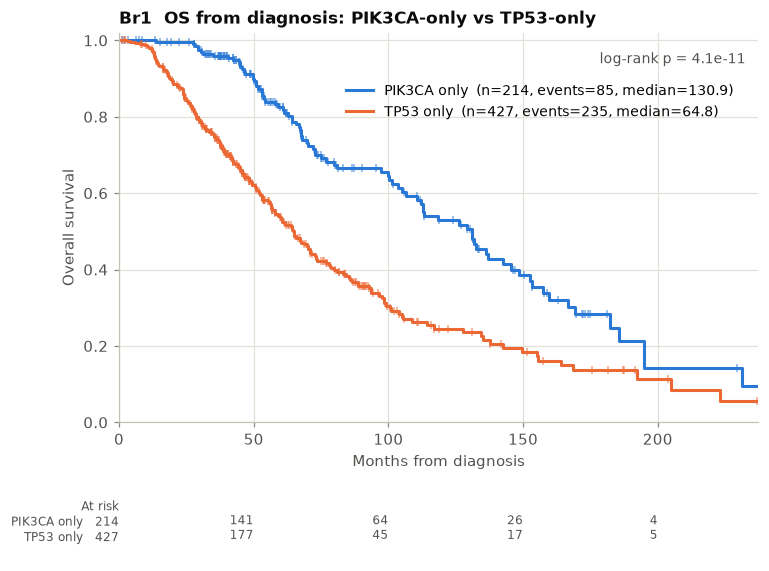

In [6]:
d1 = S.join(grp, how="inner")
d1x = d1[d1.profile.isin(["PIK3CA only", "TP53 only"])]
ax, tab1 = cb.km_plot(d1x, "profile", order=["PIK3CA only", "TP53 only"], title="Br1  OS from diagnosis: PIK3CA-only vs TP53-only", xlabel="Months from diagnosis")
h1 = cb.hr(d1x.assign(feat=(d1x.profile == "TP53 only")), "feat", entry="entry")
h1s = cb.hr(d1x.assign(feat=(d1x.profile == "TP53 only")), "feat", entry="entry", adjust=["bca_subtype", "stage_dx", "age_dx"])
tab1["HR_LT_tp53_vs_pik3ca"] = h1["HR"]; tab1["HR_adj_subtype_stage_age"] = h1s["HR"]; tab1["p_adj"] = h1s["p_cox"]
cb.save(DS, "Br1", table=tab1, fig=ax.figure, slug="pik3ca_only_vs_tp53_only")
display(tab1)

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,neither,381,157,113,0.997,0.97,0.807,1.55e-18
1,PIK3CA only,214,85,131,1,0.995,0.826,1.55e-18
2,TP53 only,427,235,64.8,0.976,0.86,0.537,1.55e-18
3,both,108,68,66.2,0.991,0.913,0.528,1.55e-18


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_tp53_vs_pik3ca
0,PIK3CA only,183,69,119,1,1,0.844,4.92e-10,3.03
1,TP53 only,153,88,69.8,0.973,0.858,0.585,4.92e-10,3.03


[Br1] replicated; holds after subtype adjustment: PIK3CA-only (n=214) median OS 130.9 vs TP53-only (n=427) 64.8 mo, log-rank p=4.1e-11, HR (LT) TP53 vs PIK3CA 2.15; adjusted for subtype, stage, age: HR 2.65 (p=6.9e-10). Within HR+/HER2−: median 118.6 vs 69.8 mo, p=4.9e-10, HR 3.03.


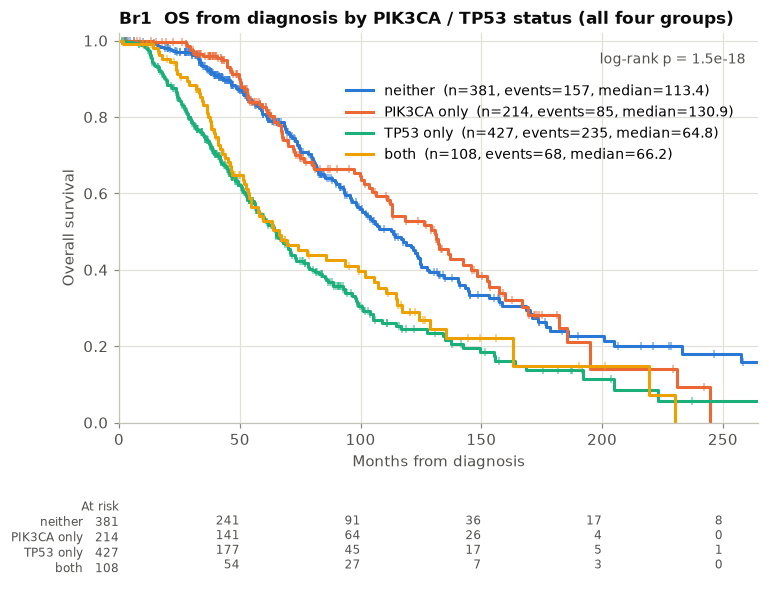

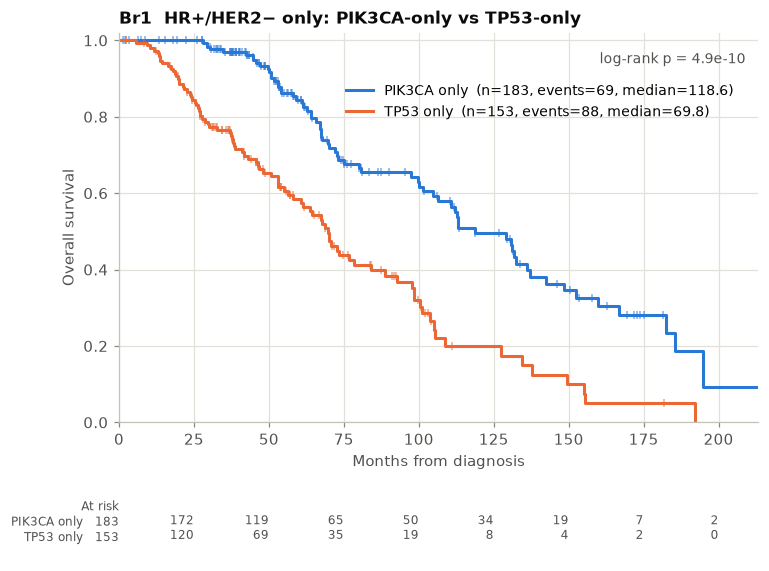

In [7]:
ax, tab1b = cb.km_plot(d1, "profile", order=order4, title="Br1  OS from diagnosis by PIK3CA / TP53 status (all four groups)", xlabel="Months from diagnosis")
cb.save(DS, "Br1", table=tab1b, fig=ax.figure, slug="four_groups")
display(tab1b)
# within HR+/HER2- only
hrpos = d1x[d1x.bca_subtype == "HR+, HER2-"]
ax, tab1c = cb.km_plot(hrpos, "profile", order=["PIK3CA only", "TP53 only"], title="Br1  HR+/HER2− only: PIK3CA-only vs TP53-only", xlabel="Months from diagnosis")
h1c = cb.hr(hrpos.assign(feat=(hrpos.profile == "TP53 only")), "feat", entry="entry")
tab1c["HR_LT_tp53_vs_pik3ca"] = h1c["HR"]
cb.save(DS, "Br1", table=tab1c, fig=ax.figure, slug="hrpos_her2neg_only")
display(tab1c)
cb.finding("Br1", "replicated; holds after subtype adjustment" if h1s["p_cox"] < 0.05 else "replicated; subtype-driven",
           f"PIK3CA-only (n={tab1.n[0]}) median OS {tab1.median_months[0]} vs TP53-only (n={tab1.n[1]}) {tab1.median_months[1]} mo, log-rank p={cb.fmt_p(tab1.p_logrank[0])}, "
           f"HR (LT) TP53 vs PIK3CA {h1['HR']:.2f}; adjusted for subtype, stage, age: HR {h1s['HR']:.2f} (p={cb.fmt_p(h1s['p_cox'])}). "
           f"Within HR+/HER2−: median {tab1c.median_months[0]} vs {tab1c.median_months[1]} mo, p={cb.fmt_p(tab1c.p_logrank[0])}, HR {h1c['HR']:.2f}.", F)

## Br2 — Are there treatments that improved OS in TP53-mutant patients?
For each treatment class (first regimen of that class per patient, metastatic setting), OS from regimen start in TP53-mutant vs TP53-wild-type patients. A class whose TP53-mut HR is close to 1 "closes the TP53 gap"; medians within TP53-mut show absolute outcomes. All lines are pooled, so classes are not comparable to each other (different lines and settings), only within class.

,feature,n_alt,n_wt,events_alt,events_wt,median_mut,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,CDK4/6 inhibitor,71,230,51,124,23,36.4,1.7e-06,2.24,1.61,3.12,1.81e-06,289,1.53e-05
1,fulvestrant,69,222,55,131,21.6,37.8,3.85e-06,2.41,1.74,3.35,1.21e-07,284,1.73e-05
2,tamoxifen,42,102,29,50,50,85.3,0.000115,2.28,1.41,3.67,0.000743,137,0.000344
3,capecitabine,189,248,146,161,18.8,26.4,0.000232,1.62,1.29,2.03,3e-05,424,0.000522
4,eribulin,120,119,104,90,6.4,12,0.0088,1.47,1.11,1.96,0.00795,231,0.0158
5,everolimus,32,104,26,64,19.8,31.3,0.0125,1.55,0.978,2.46,0.0621,132,0.0188
6,aromatase inhibitor,104,259,63,141,41.5,55.2,0.02,1.63,1.2,2.2,0.00152,349,0.0257
7,chemotherapy,138,161,84,91,38.7,48.4,0.268,1.41,1.04,1.9,0.026,286,0.301
8,HER2-targeted,79,52,39,21,71.8,87.4,0.41,1.52,0.883,2.61,0.131,125,0.41


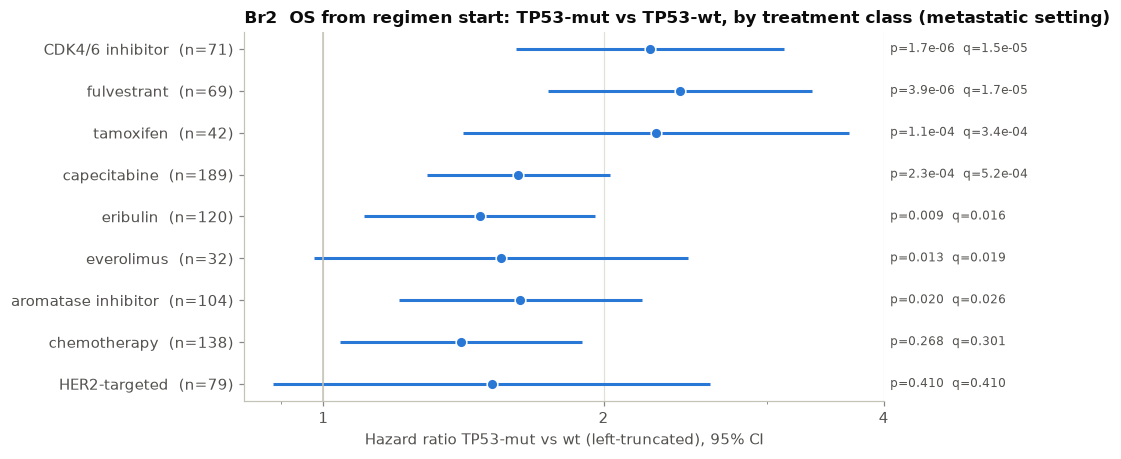

In [8]:
CLASSES = {
    "chemotherapy": dict(pattern="|".join(cb.CHEMO)),
    "aromatase inhibitor": dict(pattern="|".join(cb.AROMATASE_INHIBITORS)),
    "fulvestrant": dict(pattern="Fulvestrant"),
    "tamoxifen": dict(pattern="Tamoxifen"),
    "CDK4/6 inhibitor": dict(pattern="|".join(cb.CDK46)),
    "HER2-targeted": dict(pattern="Trastuzumab|Pertuzumab|Lapatinib|Neratinib|Tucatinib"),
    "everolimus": dict(pattern="Everolimus"),
    "capecitabine": dict(pattern="Capecitabine"),
    "eribulin": dict(pattern="Eribulin"),
    "immunotherapy": dict(pattern="|".join(cb.IO)),
}

def by_class(status, label, min_n=10):
    rows, kms = [], {}
    for name, kw in CLASSES.items():
        R = b.survival_regimen(**kw)
        R = R[R.met_setting].join(status.rename("feat"), how="inner")
        n_alt, n_wt = int(R.feat.sum()), int((~R.feat).sum())
        if n_alt < min_n or n_wt < min_n:
            continue
        R["group"] = np.where(R.feat, f"{label} mut", f"{label} wt")
        t = cb.km_table(R, "group", order=[f"{label} wt", f"{label} mut"])
        h = cb.hr(R, "feat", entry="entry")
        rows.append(dict(feature=name, n_alt=n_alt, n_wt=n_wt, events_alt=t.events[1], events_wt=t.events[0],
                         median_mut=t.median_months[1], median_wt=t.median_months[0], p_logrank=t.p_logrank[0], **h))
        kms[name] = R
    res = pd.DataFrame(rows)
    res["q_bh"] = cb.multipletests(res.p_logrank, method="fdr_bh")[1]
    return res.sort_values("p_logrank").reset_index(drop=True), kms

br2, kms2 = by_class(tp53, "TP53")
ax = cb.forest_plot(br2, top=len(br2), title="Br2  OS from regimen start: TP53-mut vs TP53-wt, by treatment class (metastatic setting)")
ax.set_xlabel("Hazard ratio TP53-mut vs wt (left-truncated), 95% CI")
cb.save(DS, "Br2", table=br2, fig=ax.figure, slug="tp53_by_treatment_class")
display(br2)

[Br2] descriptive: Within TP53-mut, median OS from regimen start (mo): HER2-targeted 71.8 (n=79), tamoxifen 50.0 (n=42), aromatase inhibitor 41.5 (n=104), chemotherapy 38.7 (n=138), CDK4/6 inhibitor 23.0 (n=71), fulvestrant 21.6 (n=69), everolimus 19.8 (n=32), capecitabine 18.8 (n=189), eribulin 6.4 (n=120). TP53-mut is worse on every class; classes where the TP53 gap is not significant (CI crosses 1, n>=20): everolimus, HER2-targeted.


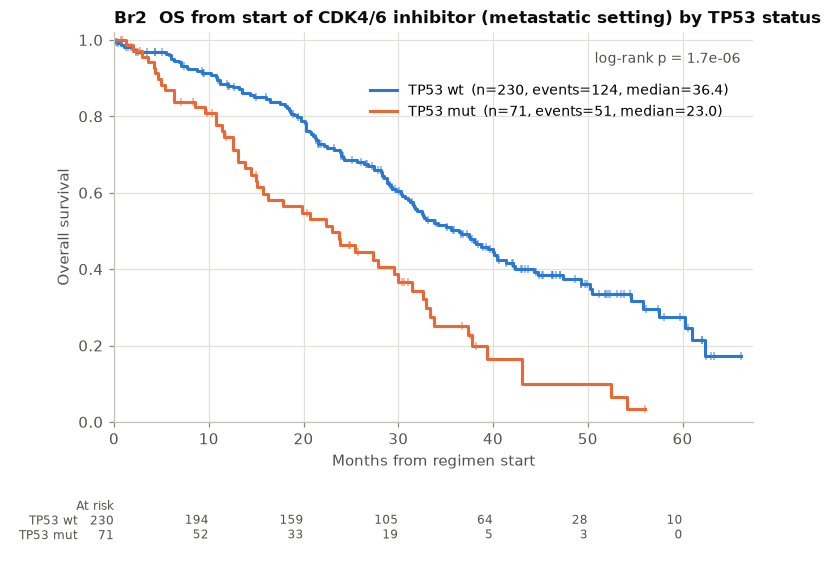

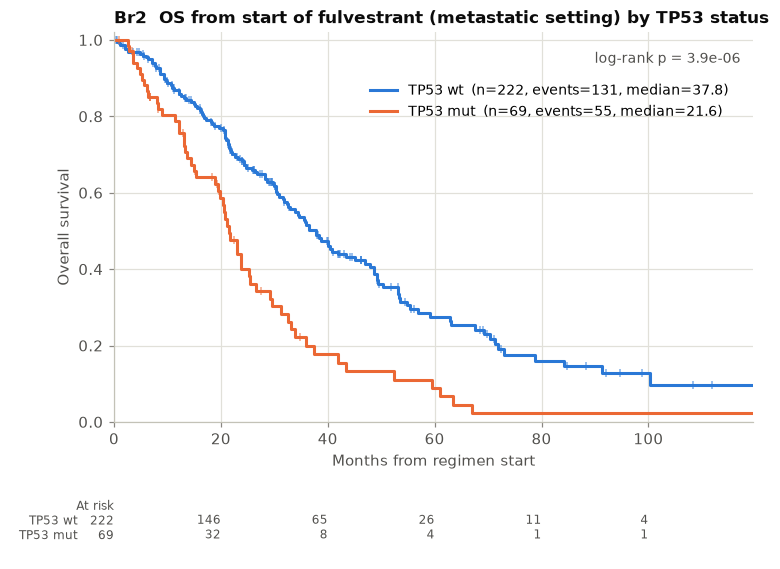

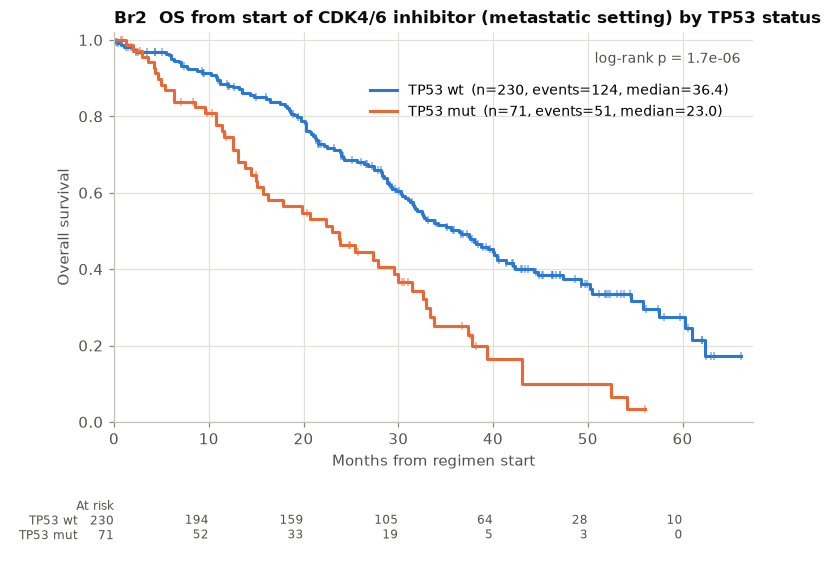

In [9]:
for name in list(br2.sort_values("p_logrank").feature[:2]) + ["CDK4/6 inhibitor"]:
    if name in kms2:
        R = kms2[name]
        ax, t = cb.km_plot(R, "group", order=["TP53 wt", "TP53 mut"], title=f"Br2  OS from start of {name} (metastatic setting) by TP53 status", xlabel="Months from regimen start")
        cb.save(DS, "Br2", table=t, fig=ax.figure, slug="km_" + re.sub(r"[^a-z0-9]+", "_", name.lower()))
closes = br2[(br2.HR_lo <= 1) & (br2.n_alt >= 20)]
cb.finding("Br2", "descriptive",
           "Within TP53-mut, median OS from regimen start (mo): " + ", ".join(f"{r.feature} {r.median_mut} (n={r.n_alt})" for r in br2.sort_values('median_mut', ascending=False).itertuples()) +
           ". TP53-mut is worse on every class; classes where the TP53 gap is not significant (CI crosses 1, n>=20): " + (", ".join(closes.feature) or "none") + ".", F)

## Br3 — Are there co-mutations in PIK3CA patients that caused worse outcomes?
Within PIK3CA-mutant patients: every co-alteration with ≥ 10 carriers / non-carriers; log-rank, left-truncated HR, BH FDR. Subtype-adjusted HR added for the hits.

,feature,gene,kind,n_alt,n_wt,events_alt,events_wt,median_alt,median_wt,p_logrank,HR,HR_lo,HR_hi,p_cox,n_cox,q_bh
0,TP53 mut,TP53,mut,108,214,68,85,66.2,131,6.65e-06,2.62,1.88,3.64,1.04e-08,304,0.000299
1,RAD21 amp,RAD21,amp,17,300,12,139,53,112,0.00859,2.58,1.41,4.72,0.00203,299,0.193
2,ROS1 mut,ROS1,mut,17,305,10,143,50.1,112,0.0245,1.79,0.929,3.44,0.0821,304,0.368
3,MDM2 amp,MDM2,amp,16,301,5,146,195,106,0.0468,0.504,0.198,1.28,0.151,299,0.526
4,MAP3K1 mut,MAP3K1,mut,35,287,13,140,131,106,0.0752,0.604,0.34,1.07,0.086,304,0.532
5,GATA3 mut,GATA3,mut,31,291,12,141,195,110,0.0757,0.542,0.278,1.06,0.0734,304,0.532
6,TSC2 mut,TSC2,mut,10,312,8,145,64,112,0.0828,4.05,1.94,8.44,0.000191,304,0.532
7,NF1 mut,NF1,mut,20,302,12,141,59,112,0.126,1.9,1.04,3.47,0.037,304,0.711
8,ESR1 mut,ESR1,mut,15,307,10,143,115,107,0.168,1.33,0.677,2.62,0.406,304,0.817
9,KMT2A mut,KMT2A,mut,10,312,7,146,112,110,0.248,1.17,0.543,2.51,0.692,304,0.817


,feature,n_alt,median_alt,median_wt,HR,p_logrank,q_bh,HR_adj_subtype_stage_age
0,TP53 mut,108,66.2,131,2.62,6.65e-06,0.000299,3.83


[Br3] signal: 1 of 45 co-alterations at FDR<0.1: TP53 mut (n=108) HR 2.62, subtype-adjusted 3.83, q=0.0003


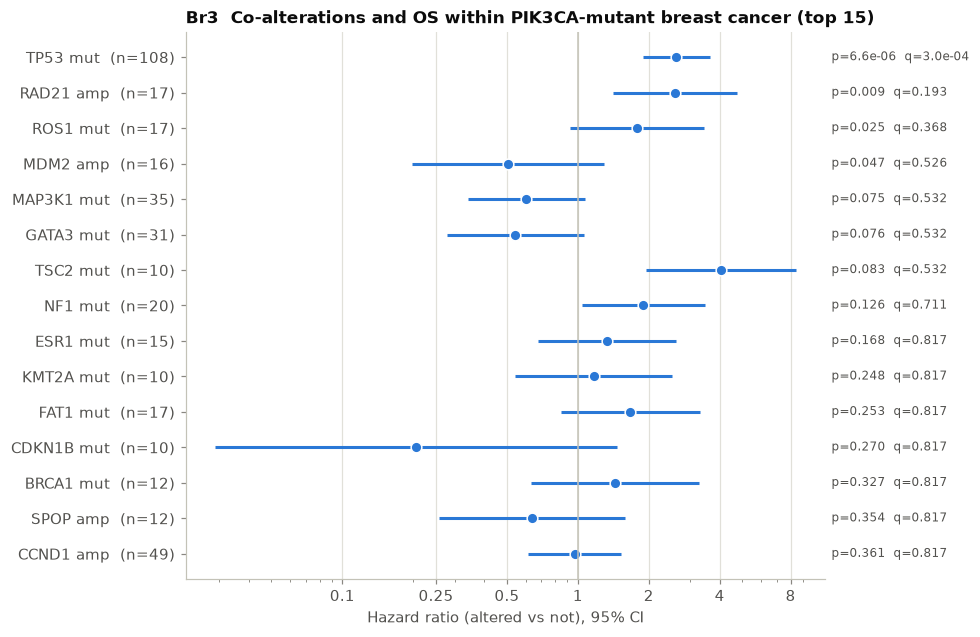

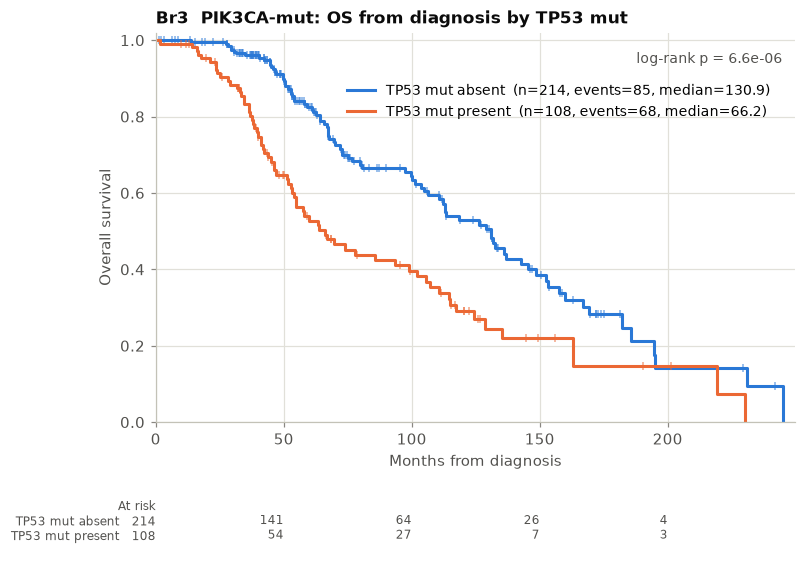

In [10]:
pik_ids = pik.index[pik]
scr3 = cb.gene_screen(S, A, kinds=("mut", "amp", "homdel"), min_n=10, entry="entry", patients=pik_ids)
scr3 = scr3[scr3.gene != "PIK3CA"].reset_index(drop=True)
ax = cb.forest_plot(scr3, top=15, title="Br3  Co-alterations and OS within PIK3CA-mutant breast cancer (top 15)")
cb.save(DS, "Br3", table=scr3, fig=ax.figure, slug="comutation_screen_in_pik3ca")
display(scr3.head(15))
hits3 = scr3[scr3.q_bh < 0.1].copy()
adj = []
for r in hits3.itertuples():
    d = S.loc[pik_ids].join(A.status(r.gene, r.kind).rename("feat"), how="inner")
    adj.append(cb.hr(d, "feat", entry="entry", adjust=["bca_subtype", "stage_dx", "age_dx"])["HR"])
hits3["HR_adj_subtype_stage_age"] = adj
display(hits3[["feature", "n_alt", "median_alt", "median_wt", "HR", "p_logrank", "q_bh", "HR_adj_subtype_stage_age"]])
for r in hits3.head(2).itertuples():
    d, t = cb.compare(S.loc[pik_ids], A.status(r.gene, r.kind), labels=(f"{r.feature} absent", f"{r.feature} present"), entry="entry")
    ax, _ = cb.km_plot(d, "group", order=[f"{r.feature} absent", f"{r.feature} present"], title=f"Br3  PIK3CA-mut: OS from diagnosis by {r.feature}", xlabel="Months from diagnosis")
    cb.save(DS, "Br3", table=t, fig=ax.figure, slug=f"pik3ca_by_{r.gene}_{r.kind}")
cb.finding("Br3", "signal" if len(hits3) else "no signal",
           (f"{len(hits3)} of {len(scr3)} co-alterations at FDR<0.1: " + "; ".join(f"{r.feature} (n={r.n_alt}) HR {r.HR:.2f}, subtype-adjusted {r.HR_adj_subtype_stage_age:.2f}, q={r.q_bh:.2g}" for r in hits3.itertuples()))
           if len(hits3) else f"none of {len(scr3)} passes FDR<0.1 (best {scr3.feature[0]} p={cb.fmt_p(scr3.p_logrank[0])})", F)

## Br4 — OS from the start of different treatments
All patients, metastatic-setting regimens, first regimen of each class per patient. Classes are not randomised comparisons: line of therapy and subtype differ between them.

,treatment,n,events,median_months,surv_1y,surv_2y,surv_5y,first_line_pct,median_line
0,HER2-targeted,131,60,80.9,0.969,0.852,0.577,51.9,1
1,tamoxifen,144,79,75.1,0.972,0.882,0.58,31.9,2
2,aromatase inhibitor,363,204,51.9,0.966,0.841,0.436,9.4,3
3,chemotherapy,299,175,45.8,0.873,0.717,0.395,53.8,1
4,fulvestrant,291,186,32.5,0.849,0.618,0.23,0.3,5
5,CDK4/6 inhibitor,301,175,32.5,0.852,0.643,0.214,3.7,4
6,everolimus,136,90,29.1,0.776,0.571,0.127,0,7
7,capecitabine,437,307,24,0.749,0.5,0.15,1.1,5
8,eribulin,239,194,8.7,0.401,0.146,0.064,0,7
9,immunotherapy,26,18,6.4,0.369,0.231,0,0,6


,n,events,median_months,surv_1y,surv_2y,surv_5y,treatment
0,68,24,91.8,1,0.92,0.746,HER2-targeted
0,161,83,62.6,0.91,0.8,0.519,chemotherapy
0,46,27,59.8,0.978,0.86,0.495,tamoxifen
0,34,19,57.5,1,0.939,0.492,aromatase inhibitor
0,11,6,52.4,1,0.9,0,CDK4/6 inhibitor


[Br4] descriptive: Median OS from regimen start (metastatic setting): HER2-targeted 80.9 mo (n=131), tamoxifen 75.1 mo (n=144), aromatase inhibitor 51.9 mo (n=363), chemotherapy 45.8 mo (n=299), fulvestrant 32.5 mo (n=291), CDK4/6 inhibitor 32.5 mo (n=301), everolimus 29.1 mo (n=136), capecitabine 24.0 mo (n=437), eribulin 8.7 mo (n=239), immunotherapy 6.4 mo (n=26).


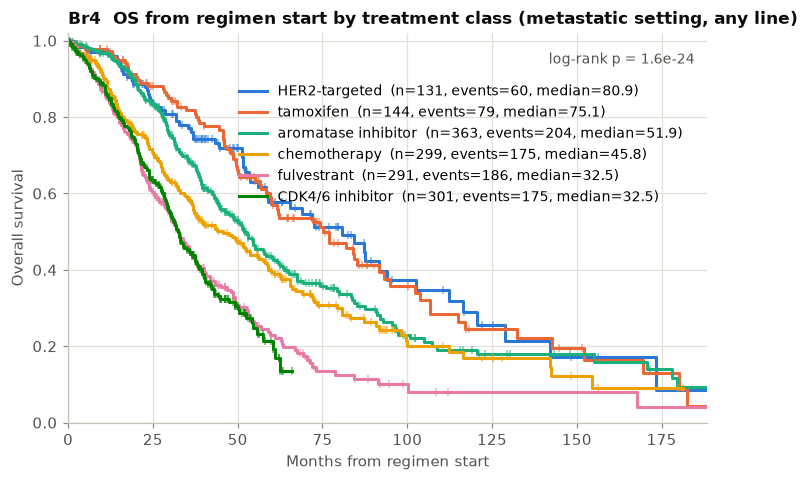

In [11]:
rows, lines = [], []
for name, kw in CLASSES.items():
    R = b.survival_regimen(**kw)
    R = R[R.met_setting]
    if len(R) < 10:
        continue
    t = cb.km_table(R.assign(g=name), "g")
    t["first_line_pct"] = round(100 * (R.line == 1).mean(), 1)
    t["median_line"] = R.line.median()
    rows.append(t)
    lines.append(R.assign(treatment=name))
br4 = pd.concat(rows).drop(columns=["p_logrank"]).rename(columns={"group": "treatment"}).sort_values("median_months", ascending=False).reset_index(drop=True)
d4 = pd.concat(lines)
top5 = br4.treatment[:6].tolist()
ax, _ = cb.km_plot(d4[d4.treatment.isin(top5)], "treatment", order=top5, title="Br4  OS from regimen start by treatment class (metastatic setting, any line)", xlabel="Months from regimen start", risk_table=False)
cb.save(DS, "Br4", table=br4, fig=ax.figure, slug="os_by_treatment_class")
display(br4)
# same thing restricted to first-line metastatic regimens
d4f = d4[d4.line == 1]
t4f = pd.concat([cb.km_table(g.assign(g=n), "g").assign(treatment=n) for n, g in d4f.groupby("treatment") if len(g) >= 10]).drop(columns=["p_logrank", "group"])
cb.save(DS, "Br4", table=t4f, slug="os_by_treatment_class_firstline")
display(t4f.sort_values("median_months", ascending=False))
cb.finding("Br4", "descriptive",
           "Median OS from regimen start (metastatic setting): " + ", ".join(f"{r.treatment} {r.median_months} mo (n={r.n})" for r in br4.itertuples()) + ".", F)

## Br5 (replicate) — PIK3CA-mut vs TP53-mut patients who received fulvestrant: no significant OS difference
cBioPortal's "OS from start of treatment" attributes are defined per **regimen**, so the deck's figure is OS from the start of the
**fulvestrant monotherapy** regimen (`Fulvestrant`), PIK3CA-only vs TP53-only (overlap dropped). That is the primary replication.
The extension uses the first **fulvestrant-containing** regimen of any kind (fulvestrant ± CDK4/6 inhibitor, everolimus, alpelisib, …), which triples the sample.

,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_tp53_vs_pik3ca,HR_lo,HR_hi,HR_adj_subtype_age
0,PIK3CA only,35,24,47.9,0.97,0.694,0.343,0.297,2.13,0.891,5.11,2.18
1,TP53 only,15,11,28.6,1,0.62,0.118,0.297,2.13,0.891,5.11,2.18


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,neither,58,42,38.3,0.862,0.695,0.223,0.413
1,PIK3CA only,35,24,47.9,0.97,0.694,0.343,0.413
2,TP53 only,15,11,28.6,1,0.62,0.118,0.413
3,both,8,7,29.5,0.875,0.5,0.167,0.413


line,2,3,4+
profile,,,
PIK3CA only,1,4,30
TP53 only,1,2,12


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_tp53_vs_pik3ca,HR_lo,HR_hi,HR_adj_subtype_age
0,PIK3CA only,77,44,43.4,0.901,0.695,0.303,0.000158,2.72,1.7,4.36,2.81
1,TP53 only,46,36,22.9,0.817,0.387,0.069,0.000158,2.72,1.7,4.36,2.81


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,neither,145,87,35.5,0.851,0.677,0.259,7.29e-05
1,PIK3CA only,77,44,43.4,0.901,0.695,0.303,7.29e-05
2,TP53 only,46,36,22.9,0.817,0.387,0.069,7.29e-05
3,both,23,19,20.8,0.737,0.423,0.127,7.29e-05


line,2,3,4+
profile,,,
PIK3CA only,3,9,65
TP53 only,1,6,39


[Br5] replicated (underpowered); difference appears with any fulvestrant-containing regimen: Fulvestrant monotherapy regimen: PIK3CA-only n=35 median 47.9 vs TP53-only n=15 median 28.6 mo, log-rank p=0.297, HR (LT) 2.13. Any fulvestrant-containing regimen: n=77 vs 46, median 43.4 vs 22.9 mo, p=1.6e-04, HR (LT) 2.72, subtype/age-adjusted 2.81.


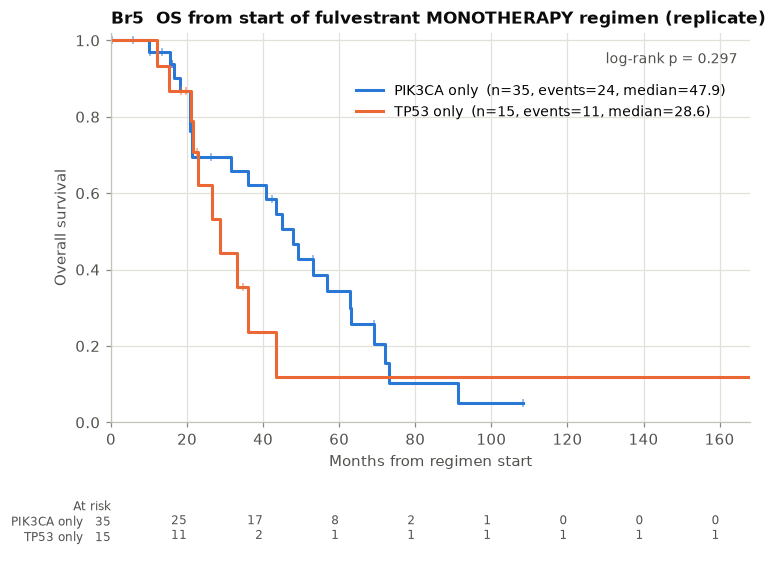

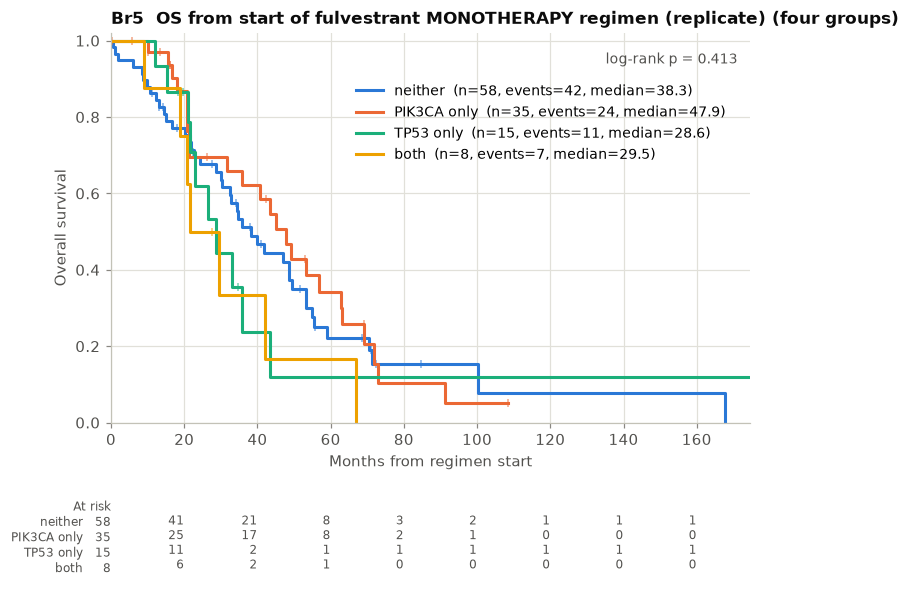

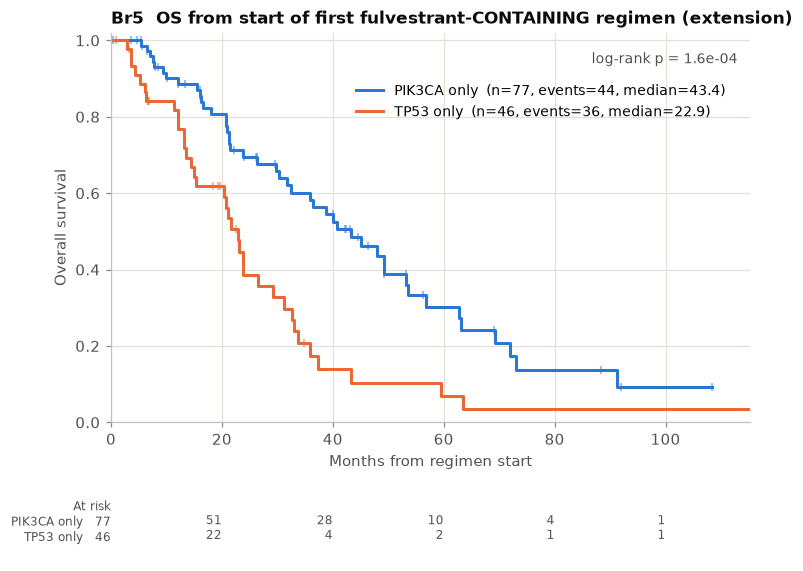

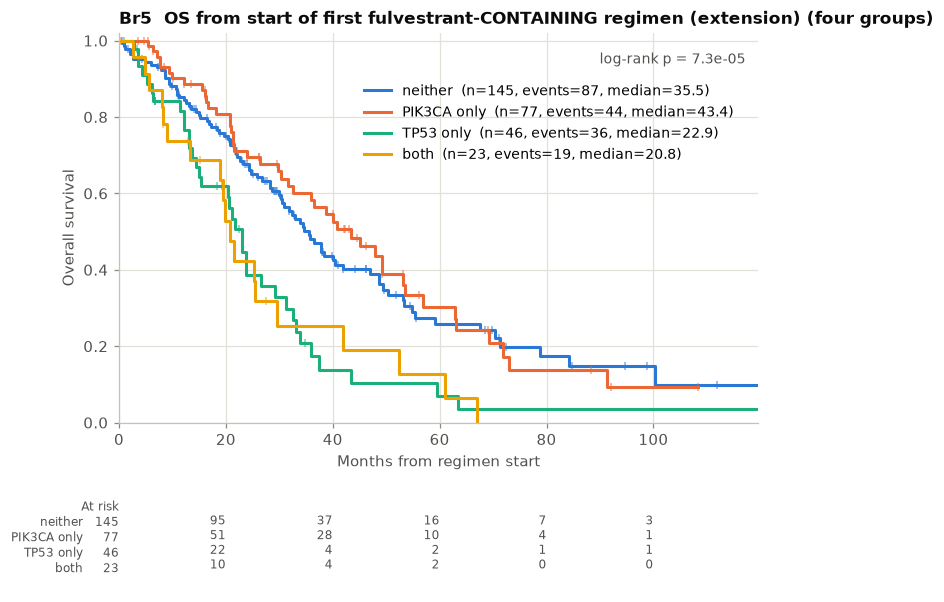

In [12]:
def regimen_groups(R, title, qid, slug):
    d = R.join(grp, how="inner")
    dx = d[d.profile.isin(["PIK3CA only", "TP53 only"])]
    ax, t = cb.km_plot(dx, "profile", order=["PIK3CA only", "TP53 only"], title=title, xlabel="Months from regimen start")
    h = cb.hr(dx.assign(feat=(dx.profile == "TP53 only")), "feat", entry="entry")
    hs = cb.hr(dx.join(S[["bca_subtype", "age_dx"]]).assign(feat=(dx.profile == "TP53 only")), "feat", entry="entry", adjust=["bca_subtype", "age_dx"])
    t["HR_LT_tp53_vs_pik3ca"] = h["HR"]; t["HR_lo"] = h["HR_lo"]; t["HR_hi"] = h["HR_hi"]; t["HR_adj_subtype_age"] = hs["HR"]
    cb.save(DS, qid, table=t, fig=ax.figure, slug=slug)
    display(t)
    ax, t4 = cb.km_plot(d, "profile", order=order4, title=title + " (four groups)", xlabel="Months from regimen start")
    cb.save(DS, qid, table=t4, fig=ax.figure, slug=slug + "_four_groups")
    display(t4)
    display(pd.crosstab(dx.profile, dx.line.clip(upper=4).astype(int).astype(str).replace("4", "4+")).rename_axis(columns="line"))
    return t, h, hs

Rf = b.survival_regimen(exact="Fulvestrant"); Rf = Rf[Rf.met_setting]
t5, h5, h5s = regimen_groups(Rf, "Br5  OS from start of fulvestrant MONOTHERAPY regimen (replicate)", "Br5", "fulvestrant_mono_pik3ca_vs_tp53")
Rfa = b.survival_regimen(pattern="Fulvestrant"); Rfa = Rfa[Rfa.met_setting]
t5a, h5a, h5as = regimen_groups(Rfa, "Br5  OS from start of first fulvestrant-CONTAINING regimen (extension)", "Br5", "fulvestrant_any_pik3ca_vs_tp53")
cb.finding("Br5", ("replicated (underpowered)" if t5.p_logrank[0] > 0.05 else "not replicated") + ("; difference appears with any fulvestrant-containing regimen" if t5a.p_logrank[0] < 0.05 else ""),
           f"Fulvestrant monotherapy regimen: PIK3CA-only n={t5.n[0]} median {t5.median_months[0]} vs TP53-only n={t5.n[1]} median {t5.median_months[1]} mo, "
           f"log-rank p={cb.fmt_p(t5.p_logrank[0])}, HR (LT) {h5['HR']:.2f}. Any fulvestrant-containing regimen: n={t5a.n[0]} vs {t5a.n[1]}, median {t5a.median_months[0]} vs {t5a.median_months[1]} mo, "
           f"p={cb.fmt_p(t5a.p_logrank[0])}, HR (LT) {h5a['HR']:.2f}, subtype/age-adjusted {h5as['HR']:.2f}.", F)

## Br6 (replicate) — On fulvestrant + palbociclib, PIK3CA-mut OS was better than TP53-mut
OS from the start of the `Fulvestrant, Palbociclib` regimen (the per-regimen attribute cBioPortal exposes), metastatic setting.

patients with a 'Fulvestrant, Palbociclib' regimen in the metastatic setting: 119; 12 further patients received the pair only inside a larger combination (not counted)


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank,HR_LT_tp53_vs_pik3ca,HR_lo,HR_hi,HR_adj_subtype_age
0,PIK3CA only,32,15,36.4,0.903,0.746,0.165,0.0012,3.17,1.49,6.75,4.22
1,TP53 only,17,15,23,0.75,0.347,0,0.0012,3.17,1.49,6.75,4.22


,group,n,events,median_months,surv_1y,surv_2y,surv_5y,p_logrank
0,neither,63,33,31.8,0.867,0.641,0.273,0.00296
1,PIK3CA only,32,15,36.4,0.903,0.746,0.165,0.00296
2,TP53 only,17,15,23,0.75,0.347,0,0.00296
3,both,7,6,19.8,0.571,0.381,0,0.00296


line,3,4+
profile,,
PIK3CA only,6,26
TP53 only,4,13


[Br6] replicated: Fulvestrant+palbociclib: PIK3CA-only n=32 median 36.4 vs TP53-only n=17 median 23.0 mo, log-rank p=0.001, HR (LT) 3.17 [1.49-6.75], subtype/age-adjusted 4.22.


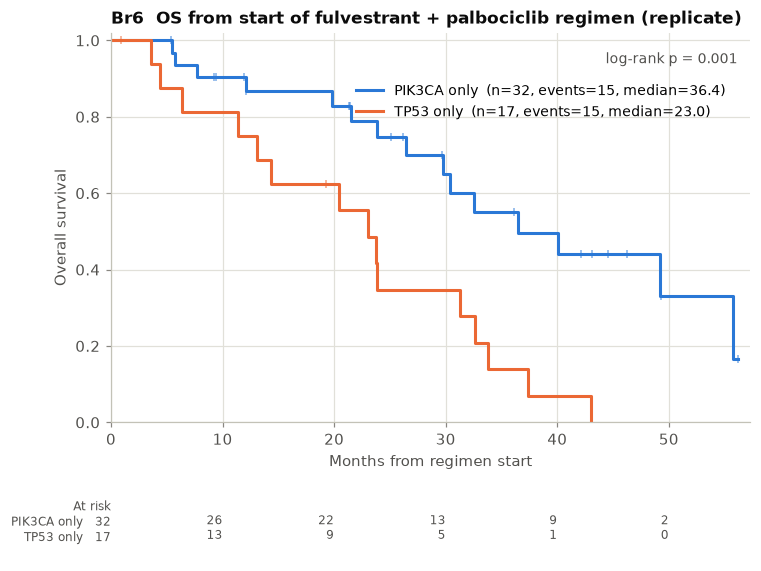

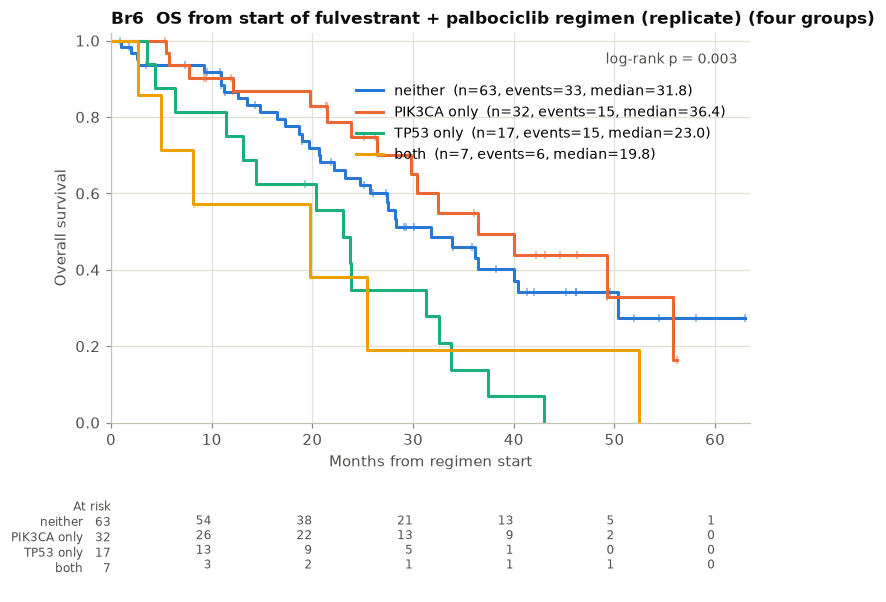

In [13]:
Rc = b.survival_regimen(exact="Fulvestrant, Palbociclib"); Rc = Rc[Rc.met_setting]
rg = b.regimens.regimen_drugs.fillna("")
n_other = b.regimens[rg.str.contains("Fulvestrant") & rg.str.contains("Palbociclib") & (rg != "Fulvestrant, Palbociclib")].record_id.nunique()
print(f"patients with a 'Fulvestrant, Palbociclib' regimen in the metastatic setting: {len(Rc)}; {n_other} further patients received the pair only inside a larger combination (not counted)")
t6, h6, h6s = regimen_groups(Rc, "Br6  OS from start of fulvestrant + palbociclib regimen (replicate)", "Br6", "fulv_palbo_pik3ca_vs_tp53")
cb.finding("Br6", "replicated" if (t6.p_logrank[0] < 0.05 and t6.median_months[0] > t6.median_months[1]) else "not replicated / underpowered",
           f"Fulvestrant+palbociclib: PIK3CA-only n={t6.n[0]} median {t6.median_months[0]} vs TP53-only n={t6.n[1]} median {t6.median_months[1]} mo, "
           f"log-rank p={cb.fmt_p(t6.p_logrank[0])}, HR (LT) {h6['HR']:.2f} [{h6['HR_lo']:.2f}-{h6['HR_hi']:.2f}], subtype/age-adjusted {h6s['HR']:.2f}.", F)

## Summary of findings

In [14]:
fd = pd.DataFrame(F)
cb.save(DS, "findings", table=fd)
pd.set_option("display.max_colwidth", 400)
fd

,question,verdict,note
0,Br1,replicated; holds after subtype adjustment,"PIK3CA-only (n=214) median OS 130.9 vs TP53-only (n=427) 64.8 mo, log-rank p=4.1e-11, HR (LT) TP53 vs PIK3CA 2.15; adjusted for subtype, stage, age: HR 2.65 (p=6.9e-10). Within HR+/HER2−: median 118.6 vs 69.8 mo, p=4.9e-10, HR 3.03."
1,Br2,descriptive,"Within TP53-mut, median OS from regimen start (mo): HER2-targeted 71.8 (n=79), tamoxifen 50.0 (n=42), aromatase inhibitor 41.5 (n=104), chemotherapy 38.7 (n=138), CDK4/6 inhibitor 23.0 (n=71), fulvestrant 21.6 (n=69), everolimus 19.8 (n=32), capecitabine 18.8 (n=189), eribulin 6.4 (n=120). TP53-mut is worse on every class; classes where the TP53 gap is not significant (CI crosses 1, n>=20): ev..."
2,Br3,signal,"1 of 45 co-alterations at FDR<0.1: TP53 mut (n=108) HR 2.62, subtype-adjusted 3.83, q=0.0003"
3,Br4,descriptive,"Median OS from regimen start (metastatic setting): HER2-targeted 80.9 mo (n=131), tamoxifen 75.1 mo (n=144), aromatase inhibitor 51.9 mo (n=363), chemotherapy 45.8 mo (n=299), fulvestrant 32.5 mo (n=291), CDK4/6 inhibitor 32.5 mo (n=301), everolimus 29.1 mo (n=136), capecitabine 24.0 mo (n=437), eribulin 8.7 mo (n=239), immunotherapy 6.4 mo (n=26)."
4,Br5,replicated (underpowered); difference appears with any fulvestrant-containing regimen,"Fulvestrant monotherapy regimen: PIK3CA-only n=35 median 47.9 vs TP53-only n=15 median 28.6 mo, log-rank p=0.297, HR (LT) 2.13. Any fulvestrant-containing regimen: n=77 vs 46, median 43.4 vs 22.9 mo, p=1.6e-04, HR (LT) 2.72, subtype/age-adjusted 2.81."
5,Br6,replicated,"Fulvestrant+palbociclib: PIK3CA-only n=32 median 36.4 vs TP53-only n=17 median 23.0 mo, log-rank p=0.001, HR (LT) 3.17 [1.49-6.75], subtype/age-adjusted 4.22."
